In [40]:
import matplotlib.pyplot as plt

#import numpy as np
import pandas as pd
from sklearn.model_selection import (
    train_test_split,  #Function to split the dataset into training and testing sets
)
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.models import Sequential


In [2]:
# This one is the Library used to import the datasets from UCI ML Repo
# This was part of the documentation of the dataset
from ucimlrepo import fetch_ucirepo

phishing_websites = fetch_ucirepo(id=327)


In [ ]:
#print(phishing_websites.metadata)
for key, value in phishing_websites.metadata.items():
    print(f"{key}: {value}")

#print(phishing_websites.variables)

uci_id: 327
name: Phishing Websites
repository_url: https://archive.ics.uci.edu/dataset/327/phishing+websites
data_url: https://archive.ics.uci.edu/static/public/327/data.csv
abstract: This dataset collected mainly from: PhishTank archive, MillerSmiles archive, Googleâ€™s searching operators.
area: Computer Science
tasks: ['Classification']
characteristics: ['Tabular']
num_instances: 11055
num_features: 30
feature_types: ['Integer']
demographics: []
target_col: ['result']
index_col: None
has_missing_values: no
missing_values_symbol: None
year_of_dataset_creation: 2012
last_updated: Tue Mar 05 2024
dataset_doi: 10.24432/C51W2X
creators: ['Rami Mohammad', 'Lee McCluskey']
intro_paper: {'ID': 396, 'type': 'NATIVE', 'title': 'An assessment of features related to phishing websites using an automated technique', 'authors': 'R. Mohammad, F. Thabtah, L. Mccluskey', 'venue': 'International Conference for Internet Technology and Secured Transactions', 'year': 2012, 'journal': None, 'DOI': None, 

In [22]:
x = phishing_websites.data.features
y = phishing_websites.data.targets.squeeze()
print(x.shape)
print(y.value_counts())
y

(11055, 30)
result
 1    6157
-1    4898
Name: count, dtype: int64


0       -1
1       -1
2       -1
3       -1
4        1
        ..
11050    1
11051   -1
11052   -1
11053   -1
11054   -1
Name: result, Length: 11055, dtype: int64

In [12]:
print(phishing_websites.variables)

                          name     role  ... units missing_values
0            having_ip_address  Feature  ...  None             no
1                   url_length  Feature  ...  None             no
2           shortining_service  Feature  ...  None             no
3             having_at_symbol  Feature  ...  None             no
4     double_slash_redirecting  Feature  ...  None             no
5                prefix_suffix  Feature  ...  None             no
6            having_sub_domain  Feature  ...  None             no
7               sslfinal_state  Feature  ...  None             no
8   domain_registration_length  Feature  ...  None             no
9                      favicon  Feature  ...  None             no
10                        port  Feature  ...  None             no
11                 https_token  Feature  ...  None             no
12                 request_url  Feature  ...  None             no
13               url_of_anchor  Feature  ...  None             no
14        

In [37]:
x

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,port,https_token,request_url,url_of_anchor,links_in_tags,sfh,submitting_to_email,abnormal_url,redirect,on_mouseover,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11050,1,-1,1,-1,1,1,1,1,-1,-1,-1,1,1,1,1,-1,-1,1,0,-1,-1,-1,-1,1,1,-1,-1,1,1,1
11051,-1,1,1,-1,-1,-1,1,-1,-1,-1,-1,1,1,-1,-1,0,-1,-1,1,-1,1,-1,1,1,1,1,1,1,-1,1
11052,1,-1,1,1,1,-1,1,-1,-1,1,1,1,1,0,-1,-1,1,1,0,1,1,1,1,1,1,1,-1,1,0,1
11053,-1,-1,1,1,1,-1,-1,-1,1,-1,1,1,-1,-1,1,-1,1,1,0,-1,1,-1,1,1,1,1,-1,1,1,1


In [26]:
y = (y == 1).astype(int)  # Convert to binary labels (0 or 1)

x_train, x_test, y_train, y_test = train_test_split(
    x, # La list of features
    y, # The list of results
    test_size=0.2, # The percentage of the dataset that will be used for testing
    random_state=42, # The random seed used to shuffle the dataset before splitting
    stratify=y # This parameter ensures that the class distribution is preserved in both the training and testing sets
)

scaler = StandardScaler()

x_train = scaler.fit_transform(x_train) # This scales the training data to have a mean of 0 and a standard deviation of 1
x_test = scaler.transform(x_test) # This scales the testing data using the same parameters as the training data

In [31]:
model = Sequential([
    Input(shape=(x_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss=BinaryCrossentropy(),
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50


249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 994us/step - accuracy: 0.8859 - loss: 0.2774 - val_accuracy: 0.9401 - val_loss: 0.1669
Epoch 2/50
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 714us/step - accuracy: 0.9353 - loss: 0.1653 - val_accuracy: 0.9435 - val_loss: 0.1457
Epoch 3/50
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 711us/step - accuracy: 0.9408 - loss: 0.1477 - val_accuracy: 0.9469 - val_loss: 0.1416
Epoch 4/50
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 708us/step - accuracy: 0.9474 - loss: 0.1333 - val_accuracy: 0.9492 - val_loss: 0.1293
Epoch 5/50
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 694us/step - accuracy: 0.9502 - loss: 0.1230 - val_accuracy: 0.9593 - val_loss: 0.1239
Epoch 6/50
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 703us/step - accuracy: 0.9550 - loss: 0.1120 - val_accuracy: 0.9503 - val_loss: 0.1224
Epoch 7/50
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.9567 - loss: 0.1035 - val_accuracy: 0.9559 - val_loss: 0.1158
Epoch 8/50
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 702us/step - accuracy: 0.9611 - loss: 0.0966 - val_accurac

In [33]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Error Rate: {1 - test_accuracy:.4f}")

Test Loss: 0.1016
Test Accuracy: 0.9706
Test Error Rate: 0.0294


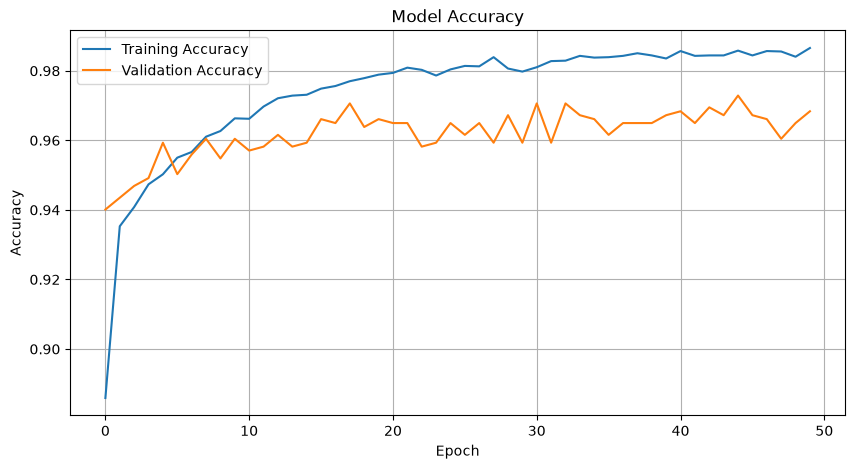

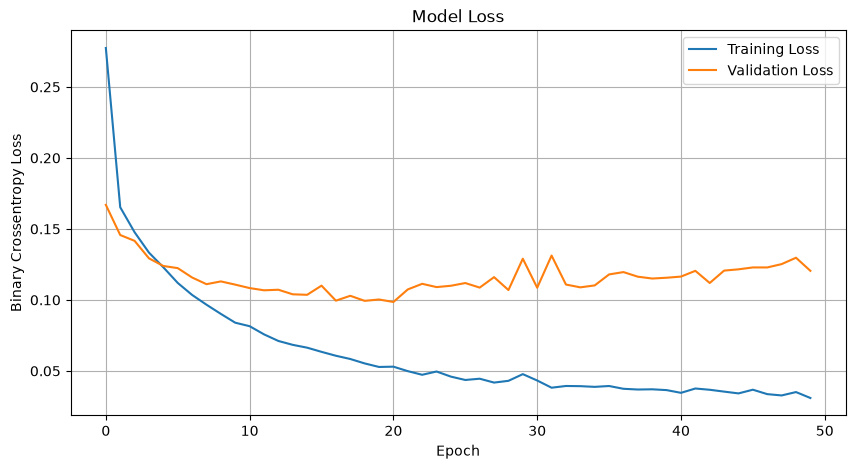

In [34]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary Crossentropy Loss')
plt.legend()
plt.grid(True)
plt.show()

# Comparison between different architectures

In [49]:
results = {}
histories = {}
models = {}

x_fit, x_val, y_fit, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

architectures = {
    "Single_Layer_8": [8],
    "Double_Layer_16_8": [16, 8],
    "Double_Layer_32_16": [32, 16],
    "Double_Layer_64_32": [64, 32],
    "Triple_Layer_32_16_8": [32, 16, 8]
}

In [50]:
for name, layers in architectures.items():
    model = Sequential()
    model.add(Input(shape=(x_train.shape[1],)))
    
    for layer_size in layers:
        model.add(Dense(layer_size, activation='relu'))
    
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(
        optimizer='adam',
        loss=BinaryCrossentropy(),
        metrics=['accuracy']
    )
    
    history = model.fit(
        x_fit,
        y_fit,
        epochs=50, # Number of epochs to train the model
        batch_size=32, # Number of samples per gradient update
        validation_data=(x_val, y_val),
        verbose=0
    )

    # Saves the best validation accuracy for each architecture and the loss and accuracy for each epoch
    histories[name] = history.history
    models[name] = model

    results[name] = {
        "Train accuracy": history.history['accuracy'][-1],
        "Validation accuracy": history.history['val_accuracy'][-1],
        "Train loss": history.history['loss'][-1],
        "Validation loss": history.history['val_loss'][-1]
    }

df_results = pd.DataFrame(results).T


In [51]:
df_results.round(4)

,Train accuracy,Validation accuracy,Train loss,Validation loss
Single_Layer_8,0.9516,0.9390,0.1147,0.1422
Double_Layer_16_8,0.9730,0.9525,0.0714,0.1237
Double_Layer_32_16,0.9830,0.9616,0.0413,0.0920
Double_Layer_64_32,0.9866,0.9627,0.0347,0.0930
Triple_Layer_32_16_8,0.9839,0.9571,0.0392,0.1186


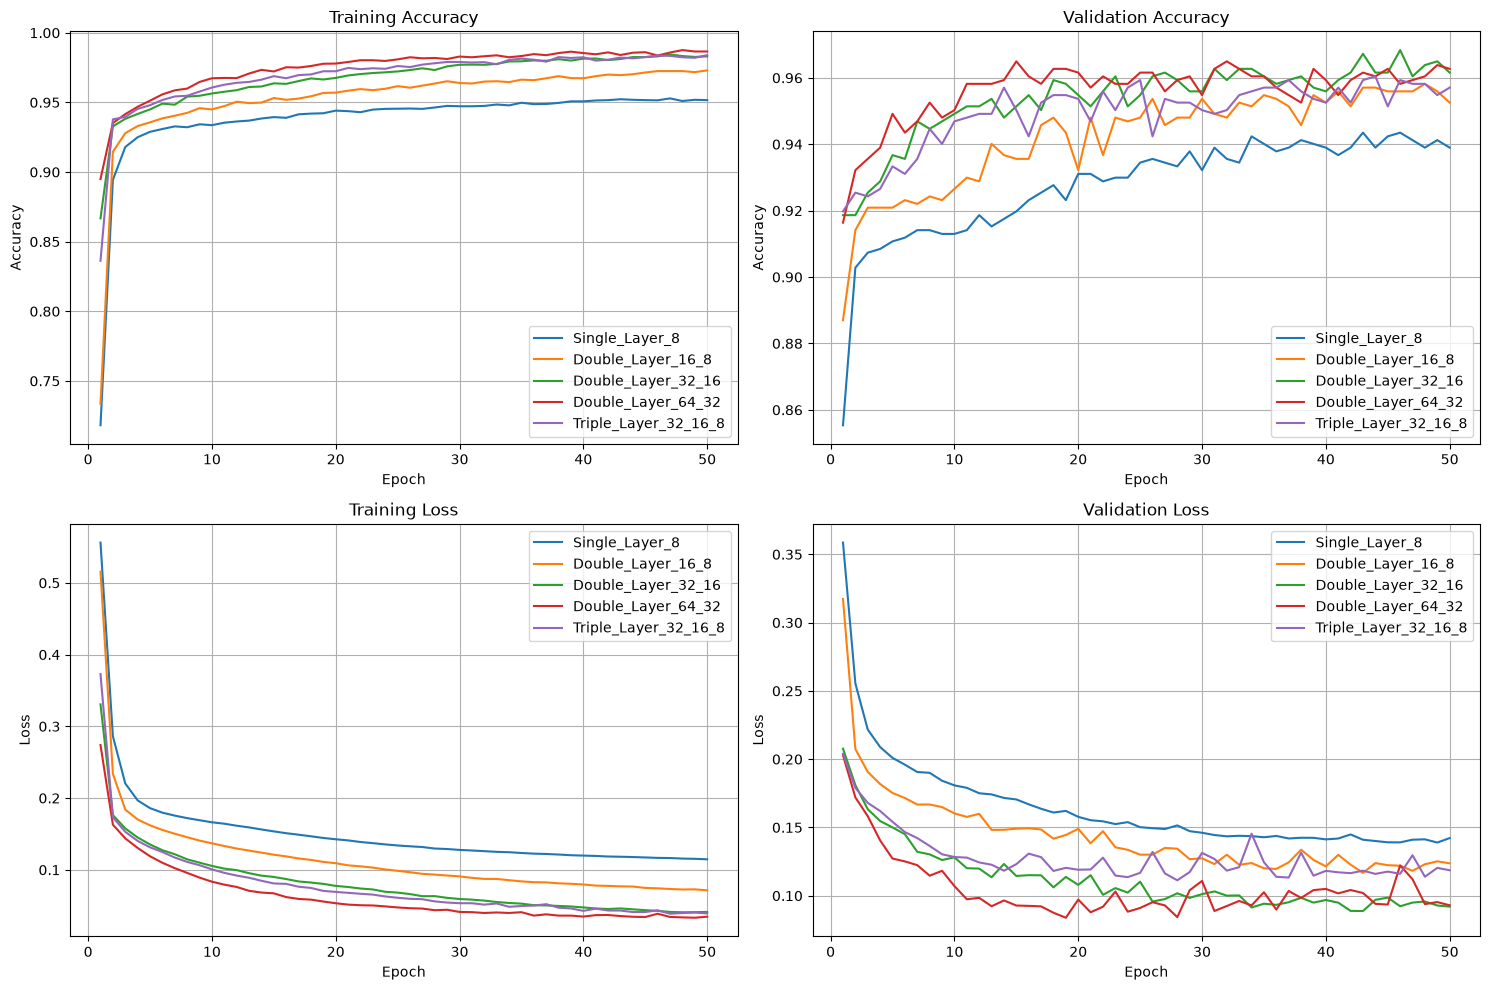

Selected architecture: Double_Layer_32_16
Test Loss: 0.09703461825847626, Test Accuracy: 0.9683400988578796


In [53]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metrics = [
    ("accuracy","Training Accuracy"),
    ("val_accuracy","Validation Accuracy"),
    ("loss","Training Loss"),
    ("val_loss","Validation Loss")
]

for ax, (metric, title) in zip(axes.flat, metrics):
    for name, history in histories.items():
        ax.plot(
            range(1,len(history[metric])+1),
            history[metric], 
            label=name
        )
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_ylabel("Accuracy" if "accuracy" in metric else "Loss")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

best_model_name = df_results['Validation loss'].idxmin()
best_model = models[best_model_name]

print("Selected architecture:", best_model_name)

test_loss, test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy}")